# 05 · Explainability and checking the explanations
1. Image SHAP (Partition explainer) on the triage-level output `p_urgent`, with a masker comparison.
2. Grad-CAM side by side, and how often the two agree.
3. Tabular SHAP on the fusion model (global beeswarm + per-patient waterfall).
4. Checks: shortcut hunt (SHAP mass inside the lesion mask, with artifact subgroups),
   deletion test (faithfulness vs. random and Grad-CAM), and stability under flips / noise.

Explanations are computed on test-split images; nothing here is used to tune the model.

In [1]:
import sys; sys.path.insert(0, "..")
import json, time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from src.artifacts import load_mask
from src.data import CLASSES, load_image, load_metadata
from src.explain import (deletion_curve, feature_groups, gradcam, grouped_urgent_shap, image_shap,
                         inside_mass, map_similarity, overlay, tabular_shap, urgent_fn)
from src.fusion import fusion_features
from src.metrics import p_urgent
from src.model import softmax_np
from src.triage import TriagePipeline

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
MASKS = "../data/masks/HAM10000_segmentations_lesion_tschandl/{}_segmentation.png"
pipe = TriagePipeline("../models")
f_u = urgent_fn(pipe.predictor)
df = load_metadata("../data/ham").set_index("image_id")
flags = pd.read_csv("../results/artifact_flags.csv").set_index("image_id")
df = df.join(flags[["dark_corners", "hair"]])
out = np.load("../models/outputs.npz", allow_pickle=True)
test = df.loc[out["test_ids"]].copy()
test_cnn = softmax_np(out["test_logits"], pipe.T)
test["p_urgent_cnn"] = p_urgent(test_cnn)
test["pred"] = np.array(CLASSES)[test_cnn.argmax(1)]
img = lambda i: load_image(df.loc[i, "path"]).astype(np.float32) / 255
rng = np.random.default_rng(0)
# QUICK=1 shrinks every sample (and SHAP budget) for a fast end-to-end check of this notebook.
import os
QUICK = os.environ.get("QUICK") == "1"
N = (lambda n: max(2, n // 10)) if QUICK else (lambda n: n)
EV = (lambda n: 100) if QUICK else (lambda n: n)

## 1 · Image SHAP on p_urgent
Red = pushes toward "see a doctor", blue = pushes toward benign.

SHAP: 7.8s per image at max_evals=2000


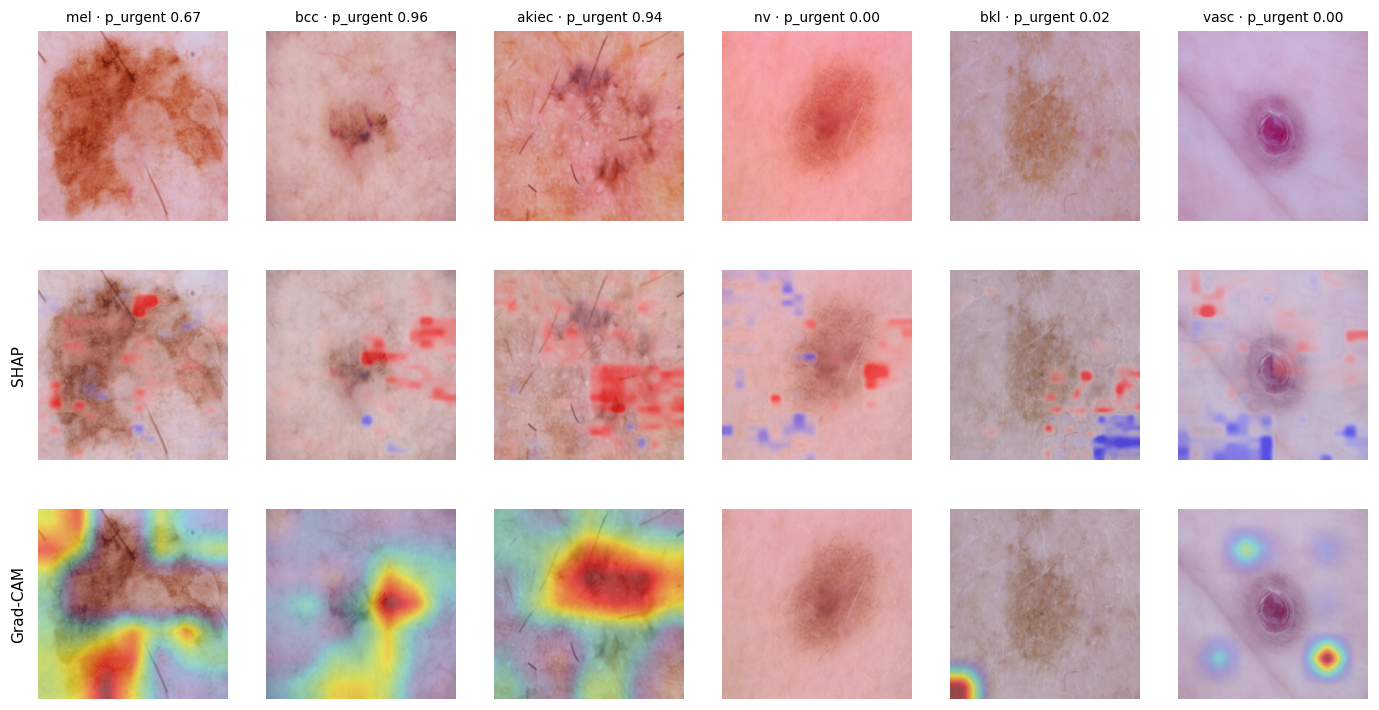

In [2]:
picks = []
for c in ["mel", "bcc", "akiec", "nv", "bkl", "vasc"]:
    cand = test[(test.dx == c) & (test.pred == c)]
    picks.append(cand.sample(1, random_state=1).index[0])

t0 = time.time()
maps = {i: image_shap(f_u, img(i), max_evals=EV(2000)) for i in picks}
cams = {i: gradcam(pipe.model, img(i), pipe.T, pipe.device) for i in picks}
print(f"SHAP: {(time.time() - t0) / len(picks):.1f}s per image at max_evals=2000")

fig, axes = plt.subplots(3, len(picks), figsize=(2.6 * len(picks), 8))
for k, i in enumerate(picks):
    axes[0, k].imshow(img(i)); axes[0, k].set_title(f"{df.dx[i]} · p_urgent {test.p_urgent_cnn[i]:.2f}", fontsize=9)
    axes[1, k].imshow(overlay(img(i), maps[i]))
    axes[2, k].imshow(overlay(img(i), cams[i], signed=False))
    for r in range(3):
        axes[r, k].axis("off")
axes[1, 0].text(-15, 112, "SHAP", rotation=90, va="center", ha="right")
axes[2, 0].text(-15, 112, "Grad-CAM", rotation=90, va="center", ha="right")
fig.savefig("../figures/shap_vs_gradcam.png")

### Masker comparison: blur vs. inpaint
A blurred lesion still looks a bit like a lesion; inpainting removes it more completely.

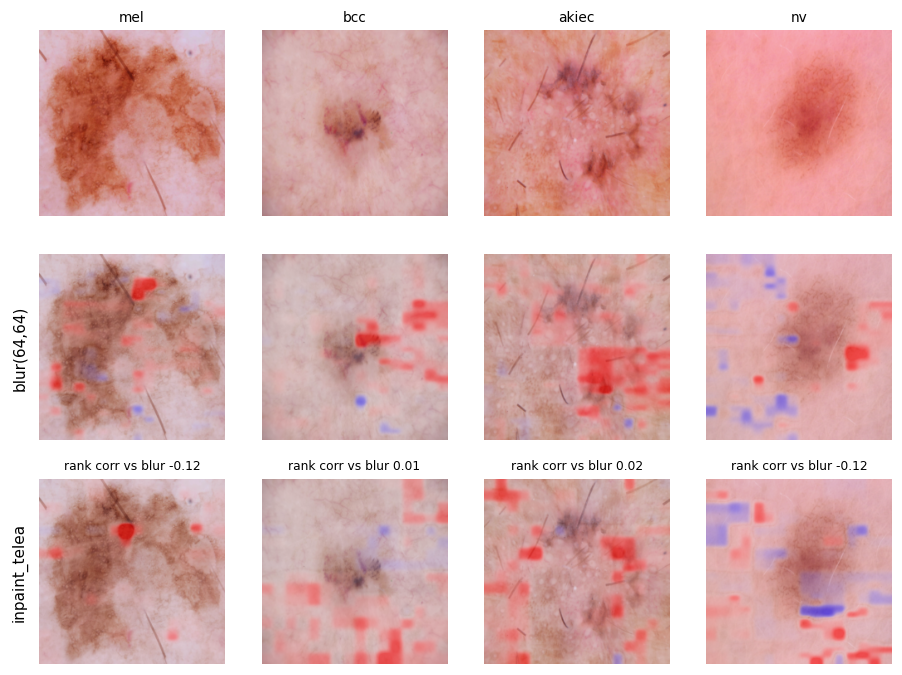

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for k, i in enumerate(picks[:4]):
    t0 = time.time()
    m_inp = image_shap(f_u, img(i), max_evals=EV(1000), masker="inpaint_telea")
    axes[0, k].imshow(img(i)); axes[0, k].set_title(df.dx[i], fontsize=9)
    axes[1, k].imshow(overlay(img(i), maps[i]))
    axes[2, k].imshow(overlay(img(i), m_inp))
    axes[2, k].set_title(f"rank corr vs blur {map_similarity(maps[i], m_inp):.2f}", fontsize=8)
for a in axes.flat: a.axis("off")
axes[1, 0].text(-15, 112, "blur(64,64)", rotation=90, va="center", ha="right")
axes[2, 0].text(-15, 112, "inpaint_telea", rotation=90, va="center", ha="right")
fig.savefig("../figures/shap_maskers.png")

## 2 · SHAP vs. Grad-CAM agreement
Rank correlation between the positive SHAP map and Grad-CAM on 40 test images the CNN calls
urgent. (For images with p_urgent ≈ 0 the softmax saturates, the Grad-CAM gradient vanishes
and its map is all zeros, so agreement is undefined there.)

In [4]:
sample = test[test.p_urgent_cnn >= pipe.cfg["tau_cnn"]].sample(N(40), random_state=2).index
agree = []
for i in sample:
    s = image_shap(f_u, img(i), max_evals=EV(500))
    g = gradcam(pipe.model, img(i), pipe.T, pipe.device)
    agree.append(map_similarity(np.clip(s, 0, None), g))
agree = np.array(agree)
print(f"SHAP vs Grad-CAM rank correlation on {np.isfinite(agree).sum()} images: median "
      f"{np.nanmedian(agree):.2f}, IQR {np.nanpercentile(agree, 25):.2f}–{np.nanpercentile(agree, 75):.2f}")

/kaggle/working/proj/notebooks/../src/explain.py:96: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return float(spearmanr(da, db).statistic)


SHAP vs Grad-CAM rank correlation on 38 images: median 0.01, IQR -0.16–0.20


## 3 · Tabular SHAP on the fusion model
Global: TreeExplainer beeswarm for the melanoma output (XGBoost margin / log-odds units).
Per patient: exact Shapley values of `p_urgent` over four feature groups (image, age, sex,
site), in probability units, so the waterfall reads "base rate → image → age → site".

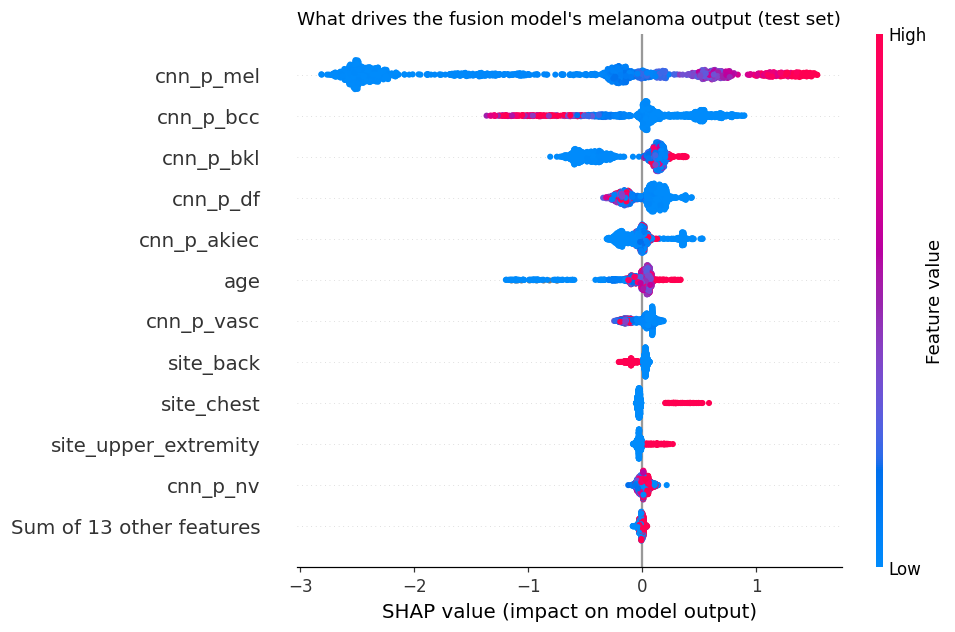

In [5]:
X_test = fusion_features(test_cnn, test.reset_index())
sv = tabular_shap(pipe.xgb, X_test)
mel = CLASSES.index("mel")
plt.figure()
shap.plots.beeswarm(sv[:, :, mel], max_display=12, show=False)
plt.title("What drives the fusion model's melanoma output (test set)")
plt.gcf().savefig("../figures/tabular_beeswarm_mel.png")

base 0.203 {'image (CNN)': np.float64(0.421), 'age': np.float64(0.007), 'sex': np.float64(0.004), 'body site': np.float64(0.004)}


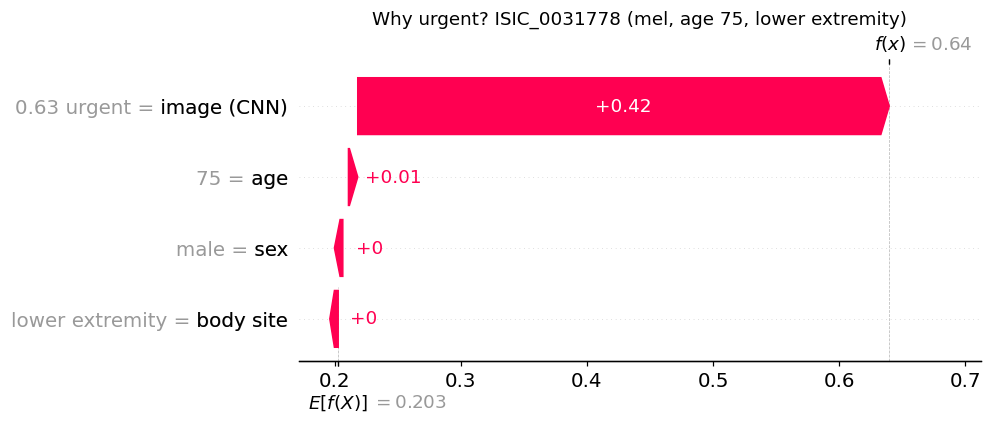

In [6]:
i_patient = test[(test.dx == "mel") & (test.age >= 60)].sample(1, random_state=3).index[0]
row = X_test.iloc[list(test.index).index(i_patient)]
expl = grouped_urgent_shap(pipe.xgb.predict_proba, row, pipe.background)
plt.figure()
shap.plots.waterfall(expl, show=False)
plt.title(f"Why urgent? {i_patient} ({df.dx[i_patient]}, age {df.age[i_patient]:.0f}, {df.localization[i_patient]})")
plt.gcf().savefig("../figures/tabular_waterfall_example.png")
print("base", round(float(expl.base_values), 3), dict(zip(expl.feature_names, np.round(expl.values, 3))))

In [7]:
# Average absolute group contribution over the test set: how much does metadata matter at all?
sub = X_test.sample(N(150), random_state=4)
contrib = np.array([grouped_urgent_shap(pipe.xgb.predict_proba, r, pipe.background).values
                    for _, r in sub.iterrows()])
group_importance = pd.Series(np.abs(contrib).mean(0), index=list(feature_groups(X_test.columns))).round(4)
group_importance

image (CNN)    0.2204
age            0.0276
sex            0.0030
body site      0.0218
dtype: float64

## 4 · Checking the explanations
### 4.1 Shortcut hunt: how much positive SHAP mass falls inside the lesion?
Lesion masks are the official HAM10000 segmentations. Computed for every test image with an
automatic artifact flag (dark corners, hair) plus a random sample of the rest.

In [8]:
art = test[test.dark_corners | test.hair]
if QUICK:
    art = art.head(6)
clean = test[~(test.dark_corners | test.hair)].groupby("dx", group_keys=False).apply(
    lambda g: g.sample(min(len(g), N(15)), random_state=5))
hunt_ids = list(dict.fromkeys(list(art.index) + list(clean.index)))
print(len(art), "artifact-flagged +", len(clean), "clean test images")

rows = []
t0 = time.time()
for i in hunt_ids:
    im = img(i)
    s = image_shap(f_u, im, max_evals=EV(500))
    m = load_mask(MASKS.format(i))
    k = 22  # corner patch size (10% of 224)
    corner = np.zeros_like(m); corner[:k, :k] = corner[:k, -k:] = corner[-k:, :k] = corner[-k:, -k:] = True
    pos = np.clip(s, 0, None)
    rows.append(dict(image_id=i, dx=df.dx[i], dark_corners=df.dark_corners[i], hair=df.hair[i],
                     lesion_area=m.mean(), inside=inside_mass(s, m),
                     corner_share=float(pos[corner].sum() / (pos.sum() + 1e-12)),
                     p_urgent=test.p_urgent_cnn[i]))
hunt = pd.DataFrame(rows).set_index("image_id")
hunt["group"] = np.select([hunt.dark_corners, hunt.hair], ["dark corners", "hair"], "no flag")
hunt.to_csv("../results/shortcut_hunt.csv")
print(f"{(time.time() - t0) / len(hunt):.1f}s per image")

/tmp/ipykernel_145/2637063251.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  clean = test[~(test.dark_corners | test.hair)].groupby("dx", group_keys=False).apply(


228 artifact-flagged + 105 clean test images


2.5s per image


In [9]:
# Expected share if SHAP mass were spread uniformly = lesion area. Ratio > 1 = lesion-focused.
by_class = hunt.groupby("dx").agg(n=("inside", "size"), inside=("inside", "median"),
                                  lesion_area=("lesion_area", "median")).round(3)
by_group = hunt.groupby("group").agg(n=("inside", "size"), inside=("inside", "median"),
                                     lesion_area=("lesion_area", "median"),
                                     corner_share=("corner_share", "median"),
                                     p_urgent=("p_urgent", "median")).round(3)
by_class, by_group

(         n  inside  lesion_area
 dx                             
 akiec   30   0.509        0.468
 bcc     32   0.238        0.211
 bkl     61   0.362        0.312
 df      16   0.486        0.314
 mel     57   0.396        0.344
 nv     118   0.233        0.183
 vasc    19   0.094        0.084,
                 n  inside  lesion_area  corner_share  p_urgent
 group                                                         
 dark corners   67   0.120        0.084         0.016     0.260
 hair          161   0.379        0.323         0.022     0.099
 no flag       105   0.265        0.249         0.025     0.371)

In [10]:
dk = hunt[hunt.dark_corners].sort_values("corner_share", ascending=False).head(6).index
fig, axes = plt.subplots(2, len(dk), figsize=(2.6 * len(dk), 5.5))
for k, i in enumerate(dk):
    s = image_shap(f_u, img(i), max_evals=EV(2000))
    axes[0, k].imshow(img(i)); axes[0, k].set_title(f"{df.dx[i]} · p_urg {test.p_urgent_cnn[i]:.2f}", fontsize=8)
    axes[1, k].imshow(overlay(img(i), s))
    m = load_mask(MASKS.format(i)); axes[1, k].contour(m, levels=[.5], colors="lime", linewidths=.8)
    axes[1, k].set_title(f"corners {hunt.corner_share[i]:.0%} · in-lesion {hunt.inside[i]:.0%}", fontsize=8)
for a in axes.flat: a.axis("off")
fig.suptitle("Shortcut hunt: dark-corner images with the most SHAP mass in the corners (green = lesion mask)", fontsize=10)
fig.savefig("../figures/shortcut_dark_corners.png")

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 3))
for g, c in [("no flag", "#7f8c8d"), ("hair", "#2471a3"), ("dark corners", "#c0392b")]:
    ax.hist(hunt.inside[hunt.group == g].dropna(), bins=20, range=(0, 1), alpha=.6, label=g, color=c, density=True)
ax.set_xlabel("share of positive SHAP mass inside lesion mask"); ax.legend(fontsize=8)
fig.savefig("../figures/shortcut_inside_hist.png")

### 4.2 Deletion test (faithfulness)
Replace the top-k% most important pixels (by SHAP, by Grad-CAM, or random) with a blurred
copy and track `p_urgent`. A faithful map makes the score fall faster than random.
Images: 50 test images the CNN calls urgent.

In [12]:
fracs = np.linspace(0, 0.5, 11)
del_ids = test[test.p_urgent_cnn >= pipe.cfg["tau_cnn"]].sample(N(50), random_state=6).index
curves = {"SHAP": [], "Grad-CAM": [], "random": []}
for i in del_ids:
    im = img(i)
    p0 = f_u(im[None])[0, 0]
    curves["SHAP"].append(deletion_curve(f_u, im, image_shap(f_u, im, max_evals=EV(500)), fracs) / p0)
    curves["Grad-CAM"].append(deletion_curve(f_u, im, gradcam(pipe.model, im, pipe.T, pipe.device), fracs) / p0)
    curves["random"].append(deletion_curve(f_u, im, None, fracs) / p0)
auc = {k: float(np.trapezoid(np.mean(v, 0), fracs) / fracs[-1]) for k, v in curves.items()}

fig, ax = plt.subplots(figsize=(4.8, 3.4))
for (k, v), c in zip(curves.items(), ["#c0392b", "#2471a3", "#7f8c8d"]):
    ax.plot(fracs * 100, np.mean(v, 0), "o-", ms=3, c=c, label=f"{k} (AUC {auc[k]:.2f})")
ax.set_xlabel("% of pixels deleted (most important first)"); ax.set_ylabel("p_urgent / original")
ax.set_title("Deletion test (lower = more faithful)", fontsize=10); ax.legend(fontsize=8)
fig.savefig("../figures/deletion_curve.png")
auc

{'SHAP': 0.30522630065679557,
 'Grad-CAM': 0.20933863744139672,
 'random': 0.47102639377117156}

### 4.3 Stability
Flip the image (and unflip the map) or add slight Gaussian noise: the map should move with
the lesion, not change its content. Rank correlation with the original map, 20 images.

In [13]:
stab = []
for i in test.sample(N(20), random_state=7).index:
    im = img(i)
    s0 = image_shap(f_u, im, max_evals=EV(1000))
    s_flip = image_shap(f_u, im[:, ::-1].copy(), max_evals=EV(1000))[:, ::-1]
    noisy = np.clip(im + rng.normal(0, 0.02, im.shape).astype(np.float32), 0, 1)
    s_noise = image_shap(f_u, noisy, max_evals=EV(1000))
    s_again = image_shap(f_u, im, max_evals=EV(1000), seed=1)
    stab.append(dict(flip=map_similarity(s0, s_flip), noise=map_similarity(s0, s_noise),
                     rerun=map_similarity(s0, s_again)))
stab = pd.DataFrame(stab)
stab.describe().loc[["mean", "50%", "min"]].round(3)

,flip,noise,rerun
mean,0.164,0.073,0.996
50%,0.145,0.050,1.000
min,-0.167,-0.338,0.961


In [14]:
json.dump({"shap_gradcam_agreement_median": float(np.nanmedian(agree)),
           "group_importance": group_importance.to_dict(),
           "shortcut_by_class": by_class.reset_index().to_dict("records"),
           "shortcut_by_group": by_group.reset_index().to_dict("records"),
           "deletion_auc": auc, "stability_median": stab.median().to_dict(),
           "waterfall_example": {"image_id": i_patient, "base": float(expl.base_values),
                                 "values": dict(zip(expl.feature_names, map(float, expl.values)))}},
          open("../results/explain.json", "w"), indent=2)